<a href="https://colab.research.google.com/github/Slim-source/Regressor-in-ML/blob/main/Regressor_in_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# Import the numpy library for high-performance multidimensional array operations
import numpy as np

# Import the datasets module and linear_model module from the scikit-learn library
from sklearn import datasets, linear_model

# Import scikit-learn's metrics module under the alias 'sm' to evaluate regression performance
import sklearn.metrics as sm

# Import matplotlib's pyplot module under the alias 'plt' for data visualization and plotting
import matplotlib.pyplot as plt

# Load the built-in diabetes toy dataset containing patient physiological measurements and disease progression targets
diabetes = datasets.load_diabetes()

# Extract the independent variables (features matrix) from the loaded dataset
input_data = diabetes.data

# Extract the dependent variable (target progression values) from the loaded dataset
output_data = diabetes.target

# Split all features except the last 20 samples to form the training feature dataset
diabetes_X_train = input_data[:-20]

# Extract the last 20 feature samples to act as the testing feature dataset
diabetes_X_test = input_data[-20:]

# Split all target progression values except the last 20 to form the training target dataset
diabetes_Y_train = output_data[:-20]

# Extract the last 20 target progression values to act as the testing target dataset
diabetes_Y_test = output_data[-20:]

Coefficients: 
 [ 3.06094248e-01 -2.37635570e+02  5.10538048e+02  3.27729878e+02
 -8.14111926e+02  4.92799595e+02  1.02841240e+02  1.84603496e+02
  7.43509388e+02  7.60966464e+01]
Mean squared error: 2004.52
Coefficient of determination (R^2): 0.59


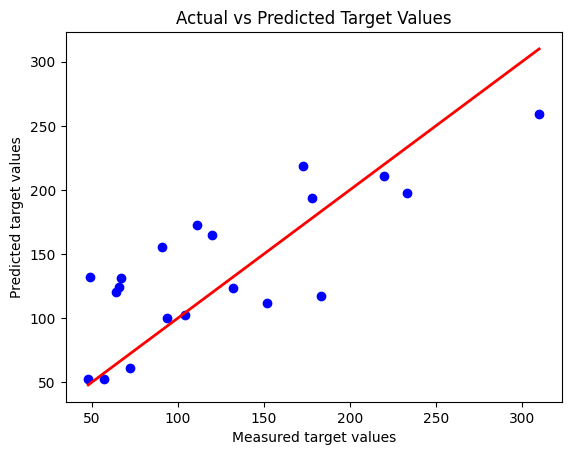

In [10]:
# Initialize a Linear Regression model object from scikit-learn
model = linear_model.LinearRegression()

# Train (fit) the linear regression model using the training feature and target datasets
model.fit(diabetes_X_train, diabetes_Y_train)

# Use the trained model to make target value predictions on the test feature dataset
diabetes_Y_pred = model.predict(diabetes_X_test)

# Print the calculated coefficients (weights) corresponding to each input feature
print('Coefficients: \n', model.coef_)

# Calculate and print the Mean Squared Error (MSE) to measure average squared prediction error
print('Mean squared error: %.2f' % sm.mean_squared_error(diabetes_Y_test, diabetes_Y_pred))

# Calculate and print the R-squared score to check the proportion of variance explained by the model
print('Coefficient of determination (R^2): %.2f' % sm.r2_score(diabetes_Y_test, diabetes_Y_pred))

# Create a scatter plot of the actual target values versus the predicted target values in blue
plt.scatter(diabetes_Y_test, diabetes_Y_pred, color='blue')

# Plot a diagonal red line representing the threshold where predictions perfectly match actual targets
plt.plot([diabetes_Y_test.min(), diabetes_Y_test.max()], [diabetes_Y_test.min(), diabetes_Y_test.max()], color='red', linewidth=2)

# Label the x-axis as the actual measured target values
plt.xlabel('Measured target values')

# Label the y-axis as the predicted target values from the model
plt.ylabel('Predicted target values')

# Set the title of the plot
plt.title('Actual vs Predicted Target Values')

# Display the final generated matplotlib plot
plt.show()

Voting Ensemble - Mean squared error: 2372.91
Voting Ensemble - Coefficient of determination (R^2): 0.51


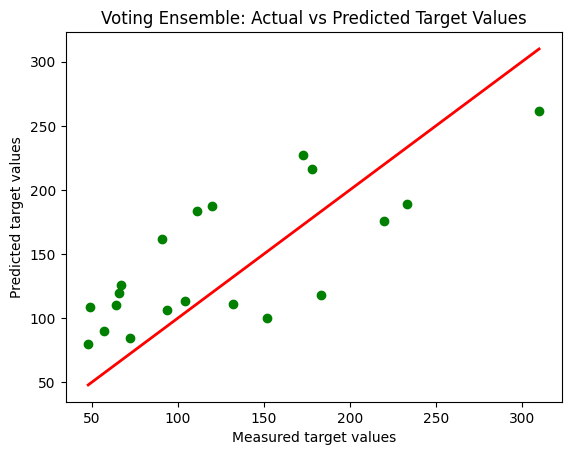

In [11]:
# Import ensemble and individual regressors from scikit-learn
from sklearn.ensemble import VotingRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge

# Initialize three diverse base models for the ensemble
reg1 = GradientBoostingRegressor(random_state=42)
reg2 = RandomForestRegressor(random_state=42)
reg3 = Ridge(alpha=1.0)

# Combine the individual models into a Voting Regressor ensemble
# By default, it averages the predictions of all three models
voting_model = VotingRegressor(estimators=[
    ('gb', reg1),
    ('rf', reg2),
    ('ridge', reg3)
])

# Train (fit) the voting ensemble model on the training datasets
voting_model.fit(diabetes_X_train, diabetes_Y_train)

# Generate predictions on the test feature set using the ensemble
diabetes_Y_pred_ensemble = voting_model.predict(diabetes_X_test)

# Print evaluation metrics for the ensemble model
print('Voting Ensemble - Mean squared error: %.2f' % sm.mean_squared_error(diabetes_Y_test, diabetes_Y_pred_ensemble))
print('Voting Ensemble - Coefficient of determination (R^2): %.2f' % sm.r2_score(diabetes_Y_test, diabetes_Y_pred_ensemble))

# Plot actual vs predicted values to visualize the performance
plt.scatter(diabetes_Y_test, diabetes_Y_pred_ensemble, color='green')
plt.plot([diabetes_Y_test.min(), diabetes_Y_test.max()], [diabetes_Y_test.min(), diabetes_Y_test.max()], color='red', linewidth=2)
plt.xlabel('Measured target values')
plt.ylabel('Predicted target values')
plt.title('Voting Ensemble: Actual vs Predicted Target Values')
plt.show()